# Ranking diagnostics: updated 120 development profiles

This analysis uses **D001-D120**, the current 378-occupation pool, and the matching weighted-dot-product and cosine `baseline_v1` evaluations. All six oracle dimensions are observed. Inputs are synthetic privileged `hidden_slots`, so these results measure ranking rather than extractor/tracker accuracy.

The previous version attempted to join the updated dataset to seven historical **60-profile** M4 evaluations. Their fingerprints differ and they cannot supply results for D061-D120. The local MiniLM cache also fails validation as stale. BM25, MiniLM, and fusion conclusions from those historical artifacts are therefore excluded here; each would require a matching new evaluation before comparison.

Run all cells with the project `.venv`. Analysis outputs are written separately under `reports/ranking/diagnostics_dev120/`. This notebook does not register diagnostic calculations in evaluation history or change ranking defaults.

In [1]:
from pathlib import Path
import os, sys, json, hashlib
ROOT = Path.cwd().resolve()
if not (ROOT / 'data/dev_profiles.jsonl').is_file():
    ROOT = ROOT.parent
assert (ROOT / 'data/dev_profiles.jsonl').is_file()
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.venv/matplotlib-cache'))
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from recommender.data_loader import read_profiles, load_eligible_occupations
from recommender.evaluation import METRICS, aggregate, evaluate_ranking
from recommender.compare import paired_comparison
from recommender.schemas import TYPES
OUT = Path('reports/ranking/diagnostics_dev120')
OUT.mkdir(parents=True, exist_ok=True)
BASE = Path('reports/ranking/dot_vs_cosine_dev120')
RUNS = {'Weighted dot product': BASE / 'weighted_dot_product', 'Cosine similarity': BASE / 'cosine_similarity'}
def read(path): return json.loads(path.read_text(encoding='utf-8'))
def sha(path): return hashlib.sha256(path.read_bytes()).hexdigest()
protected = [Path('data/dev_profiles.jsonl'), Path('data/occupations.csv'), Path('reports/ranking/evaluation_history.csv'), Path('notebooks/ranking_evaluation_history_clean.csv')]
protected += [p for folder in RUNS.values() for p in folder.rglob('*') if p.is_file()]
before = {str(p): sha(p) for p in protected}
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 20)


## Validate the comparison

Require identical dataset and input fingerprints, profile IDs, eligibility, pool, ranking depth and metric definitions. Recompute every saved metric from full predictions. No exclusions or mixing of historical datasets are allowed.

In [2]:
profiles = read_profiles(Path('data/dev_profiles.jsonl'))
assert [p['id'] for p in profiles] == [f'D{i:03}' for i in range(1, 121)]
pmap = {p['id']: p for p in profiles}
occupations = load_eligible_occupations(Path('data/occupations.csv'))
pool = {o.code for o in occupations}
assert len(pool) == 378
comparison, paired_rows = paired_comparison(RUNS['Weighted dot product'], RUNS['Cosine similarity'])
assert comparison['profiles'] == 120
manifests, rankings, metric_rows = {}, {}, []
history = pd.read_csv('reports/ranking/evaluation_history.csv')
for method, folder in RUNS.items():
    manifest = read(folder / 'manifest.json')
    manifests[method] = manifest
    for path, expected in manifest['dataset_sha256'].items(): assert sha(Path(path)) == expected, path
    assert sha(folder / 'inputs.json') == manifest['inputs_sha256']
    inputs = read(folder / 'inputs.json')
    assert len(inputs) == 120 and {r['profile_id'] for r in inputs} == set(pmap)
    for r in inputs:
        assert r['interests'] == pmap[r['profile_id']]['hidden_slots']
        assert r['user_sentences'] == [pmap[r['profile_id']]['text']]
    assert set(manifest['pool']) == pool
    assert (history.run_id == manifest['run_id']).sum() == 1
    by_id = {pid: [] for pid in pmap}
    for line in (folder / 'predictions.jsonl').read_text(encoding='utf-8').splitlines():
        r = json.loads(line)
        assert r['run_id'] == manifest['run_id']
        by_id[r['profile_id']].append(r)
    saved = {r['profile_id']: r for r in read(folder / 'per_profile.json')}
    recomputed = []
    for pid, items in by_id.items():
        items.sort(key=lambda r: r['rank'])
        codes = [r['code'] for r in items]
        assert len(codes) == len(set(codes)) == len(pool) and set(codes) == pool
        assert [r['rank'] for r in items] == list(range(1, len(pool)+1))
        p = pmap[pid]
        result = evaluate_ranking(codes, p['target'], p['related'], pool)
        for m in METRICS: assert np.isclose(result[m], saved[pid][m], atol=1e-12, rtol=0)
        recomputed.append(result)
        metric_rows.append({'profile_id': pid, 'method': method, **result})
    summary = read(folder / 'metrics.json')
    for m in METRICS: assert np.isclose(aggregate(recomputed)[m], summary[m], atol=1e-12, rtol=0)
    rankings[method] = by_id
metrics = pd.DataFrame(metric_rows)
display(pd.DataFrame([{'method': m, 'profiles': 120, 'candidates': len(pool), 'mode': manifests[m]['input_mode'], 'run_id': manifests[m]['run_id']} for m in RUNS]))


,method,profiles,candidates,mode,run_id
0,Weighted dot product,120,378,oracle,m2_structured_oracle_dev_v1_6e8d9e8b6a46475f9e...
1,Cosine similarity,120,378,oracle,m2_structured_oracle_dev_v1_48979519c810472692...


## Overall ranking results

Hit@1/5/10 requires the exact assigned target. MRR uses the full candidate ranking. NDCG@5/10 uses unchanged evaluator grades: target 4, Primary-Short 3, Primary-Long 2, Supplemental 1. Confidence intervals below use 2,000 paired profile bootstrap samples, seed 425, for cosine minus dot product.

,hit_at_1,hit_at_5,hit_at_10,mrr,ndcg_at_5,ndcg_at_10
method,,,,,,
Weighted dot product,0.050000,0.166667,0.383333,0.141508,0.149974,0.195757
Cosine similarity,0.416667,0.683333,0.783333,0.539974,0.413876,0.421261


,mean_difference,ci95,improved,regressed
hit_at_1,0.366667,"[0.275, 0.4583333333333333]",46,2
hit_at_5,0.516667,"[0.4166666666666667, 0.6166666666666667]",65,3
hit_at_10,0.4,"[0.3, 0.5]",53,5
mrr,0.398466,"[0.32450650320711777, 0.47180260004836555]",97,17
ndcg_at_5,0.263903,"[0.2089259855066416, 0.3178912176352436]",93,19
ndcg_at_10,0.225504,"[0.17859583609082683, 0.27247929568479407]",97,19


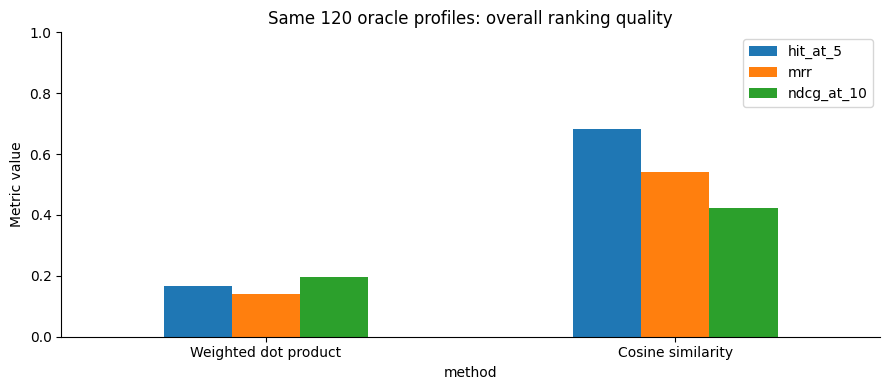

In [3]:
overall = metrics.groupby('method')[list(METRICS)].mean().reindex(RUNS)
display(overall.round(6))
ci = pd.DataFrame(comparison['metrics']).T
display(ci)
overall[['hit_at_5', 'mrr', 'ndcg_at_10']].plot.bar(rot=0, ylim=(0, 1))
plt.title('Same 120 oracle profiles: overall ranking quality'); plt.ylabel('Metric value'); plt.tight_layout(); plt.show()
overall.to_csv(OUT / 'overall_metrics.csv')
ci.to_csv(OUT / 'paired_comparison.csv')


## Updated dataset composition

D001-D060 retain their original profile content and add metadata. D061-D120 broaden top-type coverage and reshape interests into six patterns. `top_type` uses fixed R,I,A,S,E,C order to break ties. Balance of top types does not imply balance of patterns, tiers or occupation targets.

cohort,Added D061?D120,Original D001?D060
top_type,,
R,19,1
I,0,20
A,15,5
S,8,12
E,2,18
C,16,4


cohort,Added D061?D120,Original D001?D060
pattern,,
conflicting,8,3
generalist,8,0
single_dominant,13,40
three_balanced,10,0
two_strong,12,14
weak_uncertain,9,3


cohort,Added D061?D120,Original D001?D060
tier,,
1,36,36
2,24,24


,count,mean,std,min,25%,50%,75%,max
R,120.0,-0.184,1.047,-2.63,-0.952,-0.335,0.592,1.89
I,120.0,0.696,0.780,-1.07,0.138,0.685,1.300,2.60
A,120.0,0.404,0.987,-1.19,-0.272,0.115,1.038,3.00
S,120.0,0.358,1.008,-1.49,-0.342,-0.005,1.005,3.00
E,120.0,0.446,1.012,-1.57,-0.252,0.135,1.158,2.98
C,120.0,0.216,1.081,-2.00,-0.587,0.095,0.940,3.00


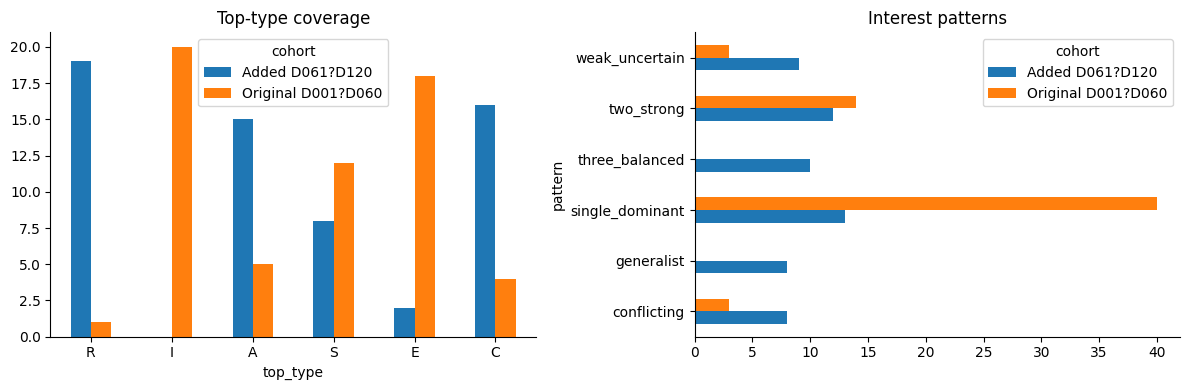

In [4]:
vectors = pd.DataFrame([p['hidden_slots'] for p in profiles], index=[p['id'] for p in profiles])[list(TYPES)]
meta = pd.DataFrame([{'profile_id': p['id'], 'cohort': 'Original D001-D060' if int(p['id'][1:]) <= 60 else 'Added D061-D120', 'top_type': p['top_type'], 'pattern': p['pattern'], 'tier': p['tier'], 'style': p['style'], 'target': p['target']} for p in profiles])
assert all(vectors.loc[r.profile_id].idxmax() == r.top_type for r in meta.itertuples())
display(pd.crosstab(meta.top_type, meta.cohort).reindex(TYPES))
display(pd.crosstab(meta.pattern, meta.cohort))
display(pd.crosstab(meta.tier, meta.cohort))
display(vectors.describe().T.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pd.crosstab(meta.top_type, meta.cohort).reindex(TYPES).plot.bar(ax=axes[0], rot=0)
pd.crosstab(meta.pattern, meta.cohort).plot.barh(ax=axes[1])
axes[0].set_title('Top-type coverage'); axes[1].set_title('Interest patterns'); plt.tight_layout(); plt.show()


## Performance by cohort, top type, pattern and tier

These are descriptive subgroup comparisons. Cohorts differ in construction and type mix, so a cohort difference cannot be attributed solely to sample size. Small pattern groups make estimates uncertain. All subgroup counts below are shown explicitly.

**By cohort**

n  hit_at_5     mrr  ndcg_at_10
cohort             method                                                
Added D061?D120    Cosine similarity     60    0.4833  0.3663      0.3145
                   Weighted dot product  60    0.1667  0.1474      0.1880
Original D001?D060 Cosine similarity     60    0.8833  0.7137      0.5280
                   Weighted dot product  60    0.1667  0.1356      0.2035

**By top_type**

n  hit_at_5     mrr  ndcg_at_10
top_type method                                                
A        Cosine similarity     20      0.65  0.6298      0.4232
         Weighted dot product  20      0.20  0.2010      0.2397
C        Cosine similarity     20      0.65  0.4455      0.3722
         Weighted dot product  20      0.10  0.0983      0.1588
E        Cosine similarity     20      0.90  0.6771      0.4768
         Weighted dot product  20      0.20  0.1642      0.2102
I        Cosine similarity     20      0.80  0.6351      0.4943
         Weighted dot product  20      0.20  0.1193      0.2297
R        Cosine similarity     20      0.35  0.2896      0.2665
         Weighted dot product  20      0.20  0.1597      0.1874
S        Cosine similarity     20      0.75  0.5626      0.4946
         Weighted dot product  20      0.10  0.1066      0.1488

**By pattern**

n  hit_at_5     mrr  ndcg_at_10
pattern         method                                                
conflicting     Cosine similarity     11    0.7273  0.5147      0.4358
                Weighted dot product  11    0.1818  0.2230      0.2401
generalist      Cosine similarity      8    0.1250  0.0566      0.0989
                Weighted dot product   8    0.1250  0.1465      0.1748
single_dominant Cosine similarity     53    0.7925  0.6311      0.4629
                Weighted dot product  53    0.2075  0.1378      0.1896
three_balanced  Cosine similarity     10    0.4000  0.3340      0.2506
                Weighted dot product  10    0.2000  0.0812      0.1452
two_strong      Cosine similarity     26    0.6923  0.5464      0.4684
                Weighted dot product  26    0.1154  0.1638      0.2107
weak_uncertain  Cosine similarity     12    0.7500  0.6410      0.4792
                Weighted dot product  12    0.0833  0.0819      0.2059

**By tier**

n  hit_at_5     mrr  ndcg_at_10
tier method                                                
1    Cosine similarity     72    0.6806  0.5301      0.4134
     Weighted dot product  72    0.1528  0.1118      0.1685
2    Cosine similarity     48    0.6875  0.5548      0.4331
     Weighted dot product  48    0.1875  0.1860      0.2367

**By style**

n  hit_at_5     mrr  ndcg_at_10
style method                                                 
full  Cosine similarity     101    0.6832  0.5388      0.4284
      Weighted dot product  101    0.1782  0.1540      0.2075
messy Cosine similarity      19    0.6842  0.5463      0.3831
      Weighted dot product   19    0.1053  0.0753      0.1335

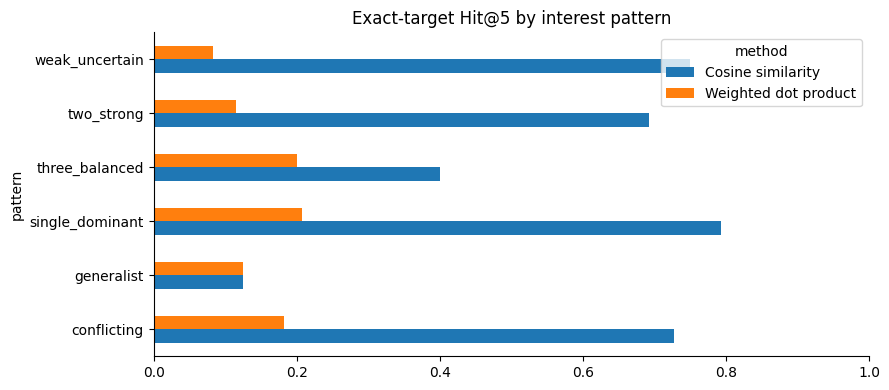

In [5]:
long = metrics.merge(meta, on='profile_id', validate='many_to_one')
subgroups = []
for attribute in ['cohort', 'top_type', 'pattern', 'tier', 'style']:
    table = long.groupby([attribute, 'method'], observed=True).agg(n=('profile_id', 'size'), hit_at_5=('hit_at_5', 'mean'), mrr=('mrr', 'mean'), ndcg_at_10=('ndcg_at_10', 'mean'))
    display(Markdown(f'**By {attribute}**')); display(table.round(4))
    subgroups.append(table.reset_index().rename(columns={attribute: 'group'}).assign(attribute=attribute))
pd.concat(subgroups, ignore_index=True).to_csv(OUT / 'subgroup_metrics.csv', index=False)
long.groupby(['pattern', 'method']).hit_at_5.mean().unstack().plot.barh(xlim=(0, 1))
plt.title('Exact-target Hit@5 by interest pattern'); plt.tight_layout(); plt.show()


## Assigned-target accuracy versus numerical fit

New profiles can be intentionally far from the target occupation average. Alongside unchanged official metrics, report two **diagnostic** hit rates: target or a Primary-Short related occupation in the top five; and target or one of the supplied `nearest_by_profile` occupations in the top five. Profile-fit labels are cosine-derived, so this measure structurally favors cosine and is not independent evidence of career suitability. These diagnostics are not added to the central history schema.

In [6]:
fit_rows = []
for method, by_id in rankings.items():
    for pid, items in by_id.items():
        p = pmap[pid]
        top5 = {r['code'] for r in items[:5]}
        short = p['related'].get('primary_short', p['related'].get('short', []))
        fit_rows.append({'profile_id': pid, 'method': method, 'related_hit_at_5': bool(top5 & ({p['target']} | set(short))), 'fit_hit_at_5': bool(top5 & ({p['target']} | set(p['nearest_by_profile'])))})
fit = pd.DataFrame(fit_rows).merge(meta, on='profile_id', validate='many_to_one')
display(fit.groupby('method')[['related_hit_at_5', 'fit_hit_at_5']].mean().round(4))
display(fit.groupby(['pattern', 'method']).agg(n=('profile_id', 'size'), related_hit_at_5=('related_hit_at_5', 'mean'), fit_hit_at_5=('fit_hit_at_5', 'mean')).round(4))
fit.to_csv(OUT / 'fit_diagnostics.csv', index=False)


,related_hit_at_5,fit_hit_at_5
method,,
Cosine similarity,0.7667,1.0000
Weighted dot product,0.3500,0.6667


n  related_hit_at_5  fit_hit_at_5
pattern         method                                                  
conflicting     Cosine similarity     11            0.8182        1.0000
                Weighted dot product  11            0.4545        0.6364
generalist      Cosine similarity      8            0.1250        1.0000
                Weighted dot product   8            0.2500        0.5000
single_dominant Cosine similarity     53            0.8491        1.0000
                Weighted dot product  53            0.3208        0.6981
three_balanced  Cosine similarity     10            0.4000        1.0000
                Weighted dot product  10            0.5000        0.6000
two_strong      Cosine similarity     26            0.8846        1.0000
                Weighted dot product  26            0.3846        0.6923
weak_uncertain  Cosine similarity     12            0.8333        1.0000
                Weighted dot product  12            0.2500        0.6667

## Numerical alignment and individual regressions

Inspect user-to-target cosine and distance separately from algorithm quality. The weighted dot product rewards magnitude as well as direction; cosine normalizes both vectors. Review cases where cosine loses as well as where it wins.

user_target_cosine        user_target_l2       
                                 mean median           mean median
cohort                                                            
Added D061?D120                 0.807  0.884          1.676  1.489
Original D001?D060              0.950  0.960          0.738  0.733

**Largest cosine regressions (negative rank improvement)**

,profile_id,cohort,top_type,pattern,tier,style,target,Cosine similarity,Weighted dot product,cosine_rank_improvement,user_target_cosine,user_target_l2,text
66,D067,Added D061?D120,A,generalist,2,full,27-1014.00,47,11,-36,0.391514,4.180034,I'm studying communications and new media at N...
94,D095,Added D061?D120,R,single_dominant,1,full,19-1023.00,28,8,-20,0.581380,2.022871,I'm in my final year of engineering and the pa...
96,D097,Added D061?D120,C,generalist,1,full,43-9081.00,173,155,-18,0.219540,3.383847,"Hmm, I'm quite open actually, lots of things a..."
78,D079,Added D061?D120,C,two_strong,2,full,15-1299.03,35,18,-17,0.781814,2.397016,I'm in my final year of statistics at NUS. I l...
89,D090,Added D061?D120,R,generalist,1,full,19-1022.00,165,151,-14,0.179058,3.321182,I'm in mechanical engineering and I really lov...
112,D113,Added D061?D120,C,two_strong,1,full,13-2041.00,20,6,-14,0.887265,1.835293,My favourite thing ever is getting a messy set...
118,D119,Added D061?D120,S,three_balanced,1,full,25-1113.00,17,5,-12,0.952943,1.480982,"I'm studying psychology with a minor in art, s..."
81,D082,Added D061?D120,R,single_dominant,2,full,17-2199.06,29,17,-12,0.615555,1.834689,"I'm studying aerospace engineering at NTU, and..."


**Largest cosine improvements**

,profile_id,cohort,top_type,pattern,tier,style,target,Cosine similarity,Weighted dot product,cosine_rank_improvement,user_target_cosine,user_target_l2,text
34,D035,Original D001?D060,S,two_strong,1,full,29-1141.03,6,103,97,0.975665,0.838443,Being there for people is what matters most to...
36,D037,Original D001?D060,S,single_dominant,1,full,25-9021.00,2,92,90,0.905488,0.941695,Helping others is what makes me happiest: my m...
58,D059,Original D001?D060,S,single_dominant,2,full,29-1141.00,1,85,84,0.939949,0.887208,I love helping and teaching people. Last year ...
50,D051,Original D001?D060,A,single_dominant,2,full,25-4012.00,1,80,79,0.950831,0.690763,"I love creating things, especially designing g..."
65,D066,Added D061?D120,A,weak_uncertain,1,messy,25-4012.00,1,80,79,0.880452,1.299089,"ermm tbh not very sure leh, maybe something wh..."
87,D088,Added D061?D120,R,three_balanced,2,full,17-2112.03,14,90,76,0.790140,1.702502,I'm studying bioengineering at NUS. Both my pa...
77,D078,Added D061?D120,A,three_balanced,2,full,19-1031.03,7,77,70,0.906442,1.149624,I'm doing a business degree at SMU on the acco...
19,D020,Original D001?D060,I,weak_uncertain,2,full,17-2112.03,1,66,65,0.807795,0.672755,I'm honestly not sure what I enjoy yet. I find...


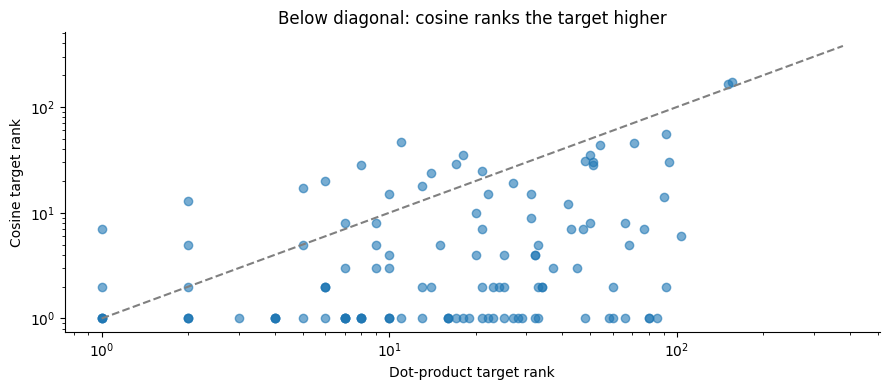

In [7]:
occ = {o.code: o for o in occupations}
alignment = []
for p in profiles:
    u = np.array([p['hidden_slots'][t] for t in TYPES])
    z = np.array([occ[p['target']].z_scores[t] for t in TYPES])
    alignment.append({'profile_id': p['id'], 'user_target_cosine': u @ z / (np.linalg.norm(u)*np.linalg.norm(z)), 'user_target_l2': np.linalg.norm(u-z)})
ranks = metrics.pivot(index='profile_id', columns='method', values='target_rank')
ranks['cosine_rank_improvement'] = ranks['Weighted dot product'] - ranks['Cosine similarity']
cases = meta.merge(ranks.reset_index(), on='profile_id').merge(pd.DataFrame(alignment), on='profile_id')
cases['text'] = cases.profile_id.map({p['id']: p['text'] for p in profiles})
display(cases.groupby('cohort')[['user_target_cosine', 'user_target_l2']].agg(['mean', 'median']).round(3))
display(Markdown('**Largest cosine regressions (negative rank improvement)**'))
display(cases.sort_values('cosine_rank_improvement').head(8))
display(Markdown('**Largest cosine improvements**'))
display(cases.sort_values('cosine_rank_improvement', ascending=False).head(8))
plt.scatter(cases['Weighted dot product'], cases['Cosine similarity'], alpha=.6)
plt.plot([1, 378], [1, 378], '--', color='gray'); plt.xscale('log'); plt.yscale('log')
plt.xlabel('Dot-product target rank'); plt.ylabel('Cosine target rank'); plt.title('Below diagonal: cosine ranks the target higher'); plt.tight_layout(); plt.show()
cases.to_csv(OUT / 'profile_diagnostics.csv', index=False)
long.to_csv(OUT / 'per_profile_metrics.csv', index=False)


## Findings and limits

The original 60-profile artifacts remain historical evidence only. Current results should be compared within this 120-profile cohort. Balance and pattern analyses explain composition; they do not establish causal effects. No held-out test profiles are read. Production algorithm selection requires separate tracker and dialogue validation.

**Cohort finding:** Cosine Hit@5 is 88.33% on D001-D060 and 48.33% on D061-D120; weighted dot product is 16.67% on each. The added cohort is more difficult under the exact assigned-target measure, while also differing in construction and type mix. This is a descriptive association, not a causal estimate.

**Fit-label caveat:** Cosine achieves 100% diagnostic fit-hit@5 because the supplied nearest occupations are themselves selected using cosine. This is useful for checking agreement with the dataset construction, but cannot independently validate cosine or career suitability.

In [8]:
dot, cos = overall.loc['Weighted dot product'], overall.loc['Cosine similarity']
display(Markdown(f"On **{len(profiles)} identical development/oracle profiles**, cosine Hit@5 is **{cos.hit_at_5:.2%}** versus **{dot.hit_at_5:.2%}** for weighted dot product. MRR is **{cos.mrr:.4f}** versus **{dot.mrr:.4f}**; NDCG@10 is **{cos.ndcg_at_10:.4f}** versus **{dot.ndcg_at_10:.4f}**. These are synthetic ranking results, not measured student outcomes."))
assert {str(p): sha(p) for p in protected} == before, 'Protected inputs or experiment artifacts changed'
(OUT / 'analysis_manifest.json').write_text(json.dumps({'profile_count': len(profiles), 'run_ids': {m: v['run_id'] for m,v in manifests.items()}, 'protected_sha256': before, 'history_rows_added_by_notebook': 0}, indent=2), encoding='utf-8')
display(Markdown('**Integrity verified:** source datasets, saved evaluations and both history files remain unchanged. Diagnostic exports are in `reports/ranking/diagnostics_dev120/`.'))


On **120 identical development/oracle profiles**, cosine Hit@5 is **68.33%** versus **16.67%** for weighted dot product. MRR is **0.5400** versus **0.1415**; NDCG@10 is **0.4213** versus **0.1958**. These are synthetic ranking results, not measured student outcomes.

**Integrity verified:** source datasets, saved evaluations and both history files remain unchanged. Diagnostic exports are in `reports/ranking/diagnostics_dev120/`.